<center> <img src = https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/hh%20label.jpg alt="drawing" style="width:400px;">

# <center> Проект: Анализ резюме из HeadHunter
   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
import re

# Исследование структуры данных

1. Прочитайте данные с помощью библиотеки Pandas. Совет: перед чтением обратите внимание на разделитель внутри файла. 

In [3]:
#ваш код здесь

df = pd.read_csv("data.csv", sep=";")

# Задание 2.1 Чему равна размерность таблицы? Введите её в виде кортежа (число строк, число столбцов).
print(df.shape)

(44744, 12)


2. Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.

In [4]:
#ваш код здесь

# Задание 2.2 Выведите несколько первых (последних) строк таблицы, чтобы убедиться в том, что ваши данные не повреждены. Ознакомьтесь с признаками и их структурой.
print(df.head())
print(df.tail())

                                   Пол, возраст           ЗП  \
0    Мужчина ,  39 лет , родился 27 ноября 1979   29000 руб.   
1     Мужчина ,  60 лет , родился 20 марта 1959   40000 руб.   
2  Женщина ,  36 лет , родилась 12 августа 1982   20000 руб.   
3      Мужчина ,  38 лет , родился 25 июня 1980  100000 руб.   
4     Женщина ,  26 лет , родилась 3 марта 1993  140000 руб.   

                           Ищет работу на должность:  \
0                            Системный администратор   
1                               Технический писатель   
2                                           Оператор   
3  Веб-разработчик (HTML / CSS / JS / PHP / базы ...   
4                  Региональный менеджер по продажам   

                        Город, переезд, командировки  \
0  Советск (Калининградская область) , не готов к...   
1  Королев , не готов к переезду , готов к редким...   
2  Тверь , не готова к переезду , не готова к ком...   
3  Саратов , не готов к переезду , готов к редким...  

3. Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице.

4. Обратите внимание на информацию о числе непустых значений.

In [5]:
#ваш код здесь

# Задание 2.3 Выведите основную информацию о числе непустых значений в столбцах и их типах в таблице. Какой тип данных имеют все столбцы?
# Задание 2.4 Обратите внимание на информацию о числе непустых значений.
print(df.info())

# Показать все строки, где есть хотя бы один пропуск
print(df[df.isnull().any(axis=1)])

################## Комментарий
# В задании на портале при вводе ответа str - выдает ошибку. Предполижительно из-за "устаревшего" ответа, где нет dtypes str

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   Пол, возраст                     44744 non-null  str  
 1   ЗП                               44744 non-null  str  
 2   Ищет работу на должность:        44744 non-null  str  
 3   Город, переезд, командировки     44744 non-null  str  
 4   Занятость                        44744 non-null  str  
 5   График                           44744 non-null  str  
 6   Опыт работы                      44576 non-null  str  
 7   Последнее/нынешнее место работы  44743 non-null  str  
 8   Последняя/нынешняя должность     44742 non-null  str  
 9   Образование и ВУЗ                44744 non-null  str  
 10  Обновление резюме                44744 non-null  str  
 11  Авто                             44744 non-null  str  
dtypes: str(12)
memory usage: 4.1 MB
None
                    

5. Выведите основную статистическую информацию о столбцах.


In [6]:
#ваш код здесь

print(df.describe())

# Задание 2.5 Выведите основную статистическую информацию о столбцах.
print(df.describe(include="all"))

                                         Пол, возраст          ЗП  \
count                                           44744       44744   
unique                                          16003         690   
top     Мужчина ,  32 года , родился 17 сентября 1986  50000 руб.   
freq                                               18        4064   

       Ищет работу на должность:  \
count                      44744   
unique                     14929   
top      Системный администратор   
freq                        3099   

                             Город, переезд, командировки         Занятость  \
count                                               44744             44744   
unique                                              10063                38   
top     Москва , не готов к переезду , не готов к кома...  полная занятость   
freq                                                 1261             30026   

             График                                        Опыт работы  \
cou

# Преобразование данных

1. Начнем с простого - с признака **"Образование и ВУЗ"**. Его текущий формат это: **<Уровень образования год выпуска ВУЗ специальность...>**. Например:
* Высшее образование 2016 Московский авиационный институт (национальный исследовательский университет)...
* Неоконченное высшее образование 2000  Балтийская государственная академия рыбопромыслового флота…
Нас будет интересовать только уровень образования.

Создайте с помощью функции-преобразования новый признак **"Образование"**, который должен иметь 4 категории: "высшее", "неоконченное высшее", "среднее специальное" и "среднее".

Выполните преобразование, ответьте на контрольные вопросы и удалите признак "Образование и ВУЗ".

Совет: обратите внимание на структуру текста в столбце **"Образование и ВУЗ"**. Гарантируется, что текущий уровень образования соискателя всегда находится в первых 2ух слов и начинается с заглавной буквы. Воспользуйтесь этим.

*Совет: проверяйте полученные категории, например, с помощью метода unique()*


In [7]:
#ваш код здесь

# Создаем новый признак: первые два слова, нижний регистр, убираем слово "образование"
df["Образование"] = (df["Образование и ВУЗ"]
                     .str.split(n=2).str[:2].str.join(" ")
                     .str.lower()
                     .str.replace(" образование", "", regex=False))

# Проверяем категории 
print("Категории признака:", df["Образование"].unique())
print("Число строк по категориям:\n", df["Образование"].value_counts())

# Удаляем исходный столбец
df = df.drop("Образование и ВУЗ", axis=1)


Категории признака: ['неоконченное высшее' 'высшее' 'среднее специальное' 'среднее']
Число строк по категориям:
 Образование
высшее                 33863
среднее специальное     5765
неоконченное высшее     4557
среднее                  559
Name: count, dtype: int64


2. Теперь нас интересует столбец **"Пол, возраст"**. Сейчас он представлен в формате **<Пол , возраст , дата рождения >**. Например:
* Мужчина , 39 лет , родился 27 ноября 1979 
* Женщина , 21 год , родилась 13 января 2000
Как вы понимаете, нам необходимо выделить каждый параметр в отдельный столбец.

Создайте два новых признака **"Пол"** и **"Возраст"**. При этом важно учесть:
* Признак пола должен иметь 2 уникальных строковых значения: "М" - мужчина, "Ж" - женщина. 
* Признак возраста должен быть представлен целыми числами.

Выполните преобразование, ответьте на контрольные вопросы и удалите признак **"Пол, возраст"** из таблицы.

*Совет: обратите внимание на структуру текста в столбце, в части на то, как разделены параметры пола, возраста и даты рождения между собой - символом " , ". 
Гарантируется, что структура одинакова для всех строк в таблице. Вы можете воспользоваться этим.*


In [8]:
# #ваш код здесь

# Разбираем столбец "Пол, возраст" на два признака: пол и возраст

# lambda не используется, т.к сложная функция
def parse_gender_age(value):
    # Если значение NaN или не строка - оба признака пустые
    if pd.isna(value) or not isinstance(value, str):
        return pd.Series([None, None])

    parts = value.split(" , ")
    # Ожидаем три части: пол, возраст со словами, дата рождения
    if len(parts) != 3:
        return pd.Series([None, None])

    gender_part, age_part = parts[0], parts[1]

    # Пол: "М" для мужчины, "Ж" для женщины, иначе пропуск
    gender = {"Мужчина": "М", "Женщина": "Ж"}.get(gender_part)

    # Возраст: первое число перед словом "год", "года" или "лет"
    match = re.search(r"(\d+)\s*(?:год|года|лет)", age_part)
    age = int(match.group(1)) if match else None

    return pd.Series([gender, age])

df[["Пол", "Возраст"]] = df["Пол, возраст"].apply(parse_gender_age)

# Преобразование типа данных столбца "Возраст" в целочисленный формат
df["Возраст"] = df["Возраст"].astype("Int64")

# Удаление исходного столбца "Пол, возраст"
df = df.drop(columns=["Пол, возраст"])

# Вывод уникальных значений для нового признака "Пол"
print("Уникальные значения Пола:", df["Пол"].unique())

# Вывод типов данных всех столбцов в таблице
print("Типы данных:\n", df.dtypes)

# Задание 3.2
# Сколько процентов женских резюме представлено в наших данных
print((df["Пол"].value_counts(normalize=True) * 100).round(2))
# Чему равен средний возраст соискателей?
print(round(df["Возраст"].mean(), 1))


Уникальные значения Пола: <StringArray>
['М', 'Ж']
Length: 2, dtype: str
Типы данных:
 ЗП                                    str
Ищет работу на должность:             str
Город, переезд, командировки          str
Занятость                             str
График                                str
Опыт работы                           str
Последнее/нынешнее место работы       str
Последняя/нынешняя должность          str
Обновление резюме                     str
Авто                                  str
Образование                        object
Пол                                   str
Возраст                             Int64
dtype: object
Пол
М    80.93
Ж    19.07
Name: proportion, dtype: float64
32.2


3. Следующим этапом преобразуем признак **"Опыт работы"**. Его текущий формат - это: **<Опыт работы: n лет m месяцев, периоды работы в различных компаниях…>**. 

Из столбца нам необходимо выделить общий опыт работы соискателя в месяцах, новый признак назовем "Опыт работы (месяц)"

Для начала обсудим условия решения задачи:
* Во-первых, в данном признаке есть пропуски. Условимся, что если мы встречаем пропуск, оставляем его как есть (функция-преобразование возвращает NaN)
* Во-вторых, в данном признаке есть скрытые пропуски. Для некоторых соискателей в столбце стоит значения "Не указано". Их тоже обозначим как NaN (функция-преобразование возвращает NaN)
* В-третьих, нас не интересует информация, которая описывается после указания опыта работы (периоды работы в различных компаниях)
* В-четвертых, у нас есть проблема: опыт работы может быть представлен только в годах или только месяцах. Например, можно встретить следующие варианты:
    * Опыт работы 3 года 2 месяца…
    * Опыт работы 4 года…
    * Опыт работы 11 месяцев…
    * Учитывайте эту особенность в вашем коде

Учитывайте эту особенность в вашем коде

В результате преобразования у вас должен получиться столбец, содержащий информацию о том, сколько месяцев проработал соискатель.
Выполните преобразование, ответьте на контрольные вопросы и удалите столбец **"Опыт работы"** из таблицы.


In [9]:
#ваш код здесь

# Создаем новый признак
df["Опыт работы (месяц)"] = df["Опыт работы"].apply(
    lambda text: None if not isinstance(text, str) or not text.strip() or text.strip().lower() == "не указано"
    else (lambda main_part:  # Берем только часть до первого двойного пробела (сама сводка опыта)
        (lambda years_match, months_match:
            None if years_match is None and months_match is None
            else (int(years_match.group(1)) if years_match else 0) * 12
                 + (int(months_match.group(1)) if months_match else 0)
        )(
            re.search(r"(\d+)\s*(?:год|года|лет)", main_part),
            re.search(r"(\d+)\s*(?:месяц|месяцев)", main_part)
        )
    )(text.replace("\xa0", " ").split("  ")[0].lower())  # Неразрывные пробелы обычные, иначе split("  ") не сработает
)

# Удаляем старый столбец
df = df.drop(columns=["Опыт работы"])

# Задание 3.3 Чему равен медианный опыт работы (в месяцах) в нашей таблице?
print("Уникальные значения в 'Опыт работы (месяц)':", df["Опыт работы (месяц)"].unique())
print("Количество пропусков:", df["Опыт работы (месяц)"].isna().sum())
print("Статистика по опыту (в месяцах):\n", df["Опыт работы (месяц)"].describe())


Уникальные значения в 'Опыт работы (месяц)': [2.020e+02 2.330e+02 1.230e+02 2.250e+02 6.700e+01 1.170e+02 2.730e+02
 4.700e+01 1.050e+02 1.980e+02 1.370e+02 5.100e+02 1.620e+02 8.300e+01
 1.700e+01 4.600e+01 1.090e+02 1.890e+02 1.140e+02 1.430e+02 5.900e+01
 6.800e+01 1.600e+02 1.380e+02 1.470e+02 1.110e+02 2.370e+02 1.780e+02
 1.120e+02 9.800e+01 1.010e+02 6.400e+01 6.100e+01 8.700e+01 2.000e+01
 2.680e+02 6.300e+01 1.940e+02 1.260e+02 3.250e+02 1.410e+02 7.400e+01
 3.000e+01 5.600e+01 2.070e+02 3.800e+01 3.030e+02 9.600e+01 6.500e+01
 1.490e+02 2.060e+02 1.800e+02 7.300e+01 3.300e+01 9.200e+01 8.600e+01
 8.000e+01 3.500e+01       nan 1.740e+02 1.300e+01 9.300e+01 3.600e+02
 6.000e+01 1.150e+02 2.900e+01 1.540e+02 1.280e+02 7.900e+01 2.300e+01
 1.070e+02 2.000e+02 1.570e+02 1.860e+02 1.720e+02 1.000e+01 1.250e+02
 1.400e+01 1.020e+02 2.090e+02 1.480e+02 2.500e+01 1.040e+02 5.100e+01
 7.800e+01 6.000e+00 1.650e+02 1.700e+02 2.190e+02 1.330e+02 2.100e+01
 9.900e+01 3.120e+02 2.960e+02 1

4. Хорошо идем! Следующий на очереди признак "Город, переезд, командировки". Информация в нем представлена в следующем виде: **<Город , (метро) , готовность к переезду (города для переезда) , готовность к командировкам>**. В скобках указаны необязательные параметры строки. Например, можно встретить следующие варианты:

* Москва , не готов к переезду , готов к командировкам
* Москва , м. Беломорская , не готов к переезду, не готов к командировкам
* Воронеж , готов к переезду (Сочи, Москва, Санкт-Петербург) , готов к командировкам

Создадим отдельные признаки **"Город"**, **"Готовность к переезду"**, **"Готовность к командировкам"**. При этом важно учесть:

* Признак **"Город"** должен содержать только 4 категории: "Москва", "Санкт-Петербург" и "город-миллионник" (их список ниже), остальные обозначьте как "другие".

    Список городов-миллионников:
    
   <code>million_cities = ['Новосибирск', 'Екатеринбург','Нижний Новгород','Казань', 'Челябинск','Омск', 'Самара', 'Ростов-на-Дону', 'Уфа', 'Красноярск', 'Пермь', 'Воронеж','Волгоград']
    </code>
    Инфорация о метро, рядом с которым проживает соискатель нас не интересует.
* Признак **"Готовность к переезду"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к переезду в признаке "Город, переезд, командировки". Например:
    * … , готов к переезду , …
    * … , не готова к переезду , …
    * … , готова к переезду (Москва, Санкт-Петербург, Ростов-на-Дону)
    * … , хочу переехать (США) , …
    
    Нас интересует только сам факт возможности или желания переезда.
* Признак **"Готовность к командировкам"** должен иметь два возможных варианта: True или False. Обратите внимание, что возможны несколько вариантов описания готовности к командировкам в признаке "Город, переезд, командировки". Например:
    * … , готов к командировкам , … 
    * … , готова к редким командировкам , …
    * … , не готов к командировкам , …
    
    Нас интересует только сам факт готовности к командировке.
    
    Еще один важный факт: при выгрузки данных у некоторых соискателей "потерялась" информация о готовности к командировкам. Давайте по умолчанию будем считать, что такие соискатели не готовы к командировкам.
    
Выполните преобразования и удалите столбец **"Город, переезд, командировки"** из таблицы.

*Совет: обратите внимание на то, что структура текста может меняться в зависимости от указания ближайшего метро. Учите это, если будете использовать порядок слов в своей программе.*


In [10]:
# Разбираем столбец "Город, переезд, командировки" на три признака

million_cities = [
    "Новосибирск", "Екатеринбург", "Нижний Новгород", "Казань", "Челябинск",
    "Омск", "Самара", "Ростов-на-Дону", "Уфа", "Красноярск", "Пермь",
    "Воронеж", "Волгоград"
]
# lambda не используется, т.к сложная функция
def get_city_category(city):
    # Категория города
    if city == "Москва":
        return "Москва"
    if city == "Санкт-Петербург":
        return "Санкт-Петербург"
    if city in million_cities:
        return "город-миллионник"
    return "другие"

# lambda не используется, т.к сложная функция
def parse_city_row(text):
    # Если значение не строка (NaN или иное) - город пустой, флаги False
    if not isinstance(text, str):
        return pd.Series([None, False, False])

    parts = text.split(" , ")
    city = parts[0].strip()  # город всегда в первом элементе, даже если указано метро
    text_lower = text.lower()

    # Готовность к переезду
    if "не готов к переезду" in text_lower or "не готова к переезду" in text_lower:
        relocation = False
    elif ("готов к переезду" in text_lower or "готова к переезду" in text_lower
          or "хочу переехать" in text_lower):
        relocation = True
    else:
        relocation = False

    # Готовность к командировкам
    if "не готов к командировкам" in text_lower or "не готова к командировкам" in text_lower:
        business_trips = False
    elif "командировкам" in text_lower:
        business_trips = True
    else:
        business_trips = False

    return pd.Series([get_city_category(city), relocation, business_trips])

df[["Город", "Готовность к переезду", "Готовность к командировкам"]] = (
    df["Город, переезд, командировки"].apply(parse_city_row)
)

# Удаляем старый столбец
df = df.drop(columns=["Город, переезд, командировки"])

# Задание 3.4
# Сколько процентов соискателей живут в Санкт-Петербурге?
print("Уникальные города:", df["Город"].unique())
print("Распределение по городам (в %):\n", (df["Город"].value_counts(normalize=True) * 100).round())
print("Готовность к переезду (в %):\n", (df["Готовность к переезду"].value_counts(normalize=True) * 100).round())
print("Готовность к командировкам (в %):\n", (df["Готовность к командировкам"].value_counts(normalize=True) * 100).round())

# Сколько процентов соискателей готовы одновременно и к переездам, и к командировкам?
mask = df["Готовность к переезду"] & df["Готовность к командировкам"]
print(f"Таких соискателей: {mask.sum()} ({(mask.mean() * 100).round()}%)")


Уникальные города: <StringArray>
['другие', 'Москва', 'город-миллионник', 'Санкт-Петербург']
Length: 4, dtype: str
Распределение по городам (в %):
 Город
Москва              37.0
другие              35.0
город-миллионник    16.0
Санкт-Петербург     11.0
Name: proportion, dtype: float64
Готовность к переезду (в %):
 Готовность к переезду
False    64.0
True     36.0
Name: proportion, dtype: float64
Готовность к командировкам (в %):
 Готовность к командировкам
True     71.0
False    29.0
Name: proportion, dtype: float64
Таких соискателей: 14258 (32.0%)


5. Рассмотрим поближе признаки **"Занятость"** и **"График"**. Сейчас признаки представляют собой набор категорий желаемой занятости (полная занятость, частичная занятость, проектная работа, волонтерство, стажировка) и желаемого графика работы (полный день, сменный график, гибкий график, удаленная работа, вахтовый метод).
На сайте hh.ru соискатель может указывать различные комбинации данных категорий, например:
* полная занятость, частичная занятость
* частичная занятость, проектная работа, волонтерство
* полный день, удаленная работа
* вахтовый метод, гибкий график, удаленная работа, полная занятость

Такой вариант признаков имеет множество различных комбинаций, а значит множество уникальных значений, что мешает анализу. Нужно это исправить!

Давайте создадим признаки-мигалки для каждой категории: если категория присутствует в списке желаемых соискателем, то в столбце на месте строки рассматриваемого соискателя ставится True, иначе - False.

Такой метод преобразования категориальных признаков называется One Hot Encoding и его схема представлена на рисунке ниже:
<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/ohe.jpg>
Выполните данное преобразование для признаков "Занятость" и "График", ответьте на контрольные вопросы, после чего удалите их из таблицы

In [11]:
#ваш код здесь

# Список категорий
employment_categories = [
    "полная занятость", "частичная занятость",
    "проектная работа", "волонтерство", "стажировка"
]

schedule_categories = [
    "полный день", "сменный график",
    "гибкий график", "удаленная работа", "вахтовый метод"
]

# Создаем флаги
# Переименуем колонки 
employment_flags = df["Занятость"].apply(
    lambda text: pd.Series(
        {cat: isinstance(text, str) and cat in text.lower() for cat in employment_categories}
    )
).rename(columns={cat: f"Занятость_{cat.replace(" ", "_")}" for cat in employment_categories})

# Создаем флаги
# Переименуем колонки
schedule_flags = df["График"].apply(
    lambda text: pd.Series(
        {cat: isinstance(text, str) and cat in text.lower() for cat in schedule_categories}
    )
).rename(columns={cat: f"График_{cat.replace(" ", "_")}" for cat in schedule_categories})

# Присоединяем новые признаки 
df = pd.concat([df, employment_flags, schedule_flags], axis=1)

# Удаляем исходные столбцы
df = df.drop(columns=["Занятость", "График"])


print("Проверка флагов занятости")
for col in employment_flags.columns:
    print(f"{col}: {df[col].sum()} соискателей ({df[col].mean():.2%})")

print("\nПроверка флагов графика")
for col in schedule_flags.columns:
    print(f"{col}: {df[col].sum()} соискателей ({df[col].mean():.2%})")

# Проверка, что все новые колонки - булевы
print("\nТипы новых колонок:")
print(df[list(employment_flags.columns) + list(schedule_flags.columns)].dtypes)

#  Задание 3.5 Сколько людей ищут проектную работу и волонтерство
mask = df["Занятость_проектная_работа"] & df["Занятость_волонтерство"]
print(f"Таких соискателей: {mask.sum()} ({(mask.mean() * 100).round(2)}%)")

# Сколько людей хотят работать вахтовым методом и с гибким графиком
mask = df["График_вахтовый_метод"] & df["График_гибкий_график"]
print(f"Таких соискателей: {mask.sum()} ({(mask.mean() * 100).round(2)}%)")



Проверка флагов занятости
Занятость_полная_занятость: 43284 соискателей (96.74%)
Занятость_частичная_занятость: 13136 соискателей (29.36%)
Занятость_проектная_работа: 8068 соискателей (18.03%)
Занятость_волонтерство: 486 соискателей (1.09%)
Занятость_стажировка: 2804 соискателей (6.27%)

Проверка флагов графика
График_полный_день: 41716 соискателей (93.23%)
График_сменный_график: 12725 соискателей (28.44%)
График_гибкий_график: 15584 соискателей (34.83%)
График_удаленная_работа: 15022 соискателей (33.57%)
График_вахтовый_метод: 3084 соискателей (6.89%)

Типы новых колонок:
Занятость_полная_занятость       bool
Занятость_частичная_занятость    bool
Занятость_проектная_работа       bool
Занятость_волонтерство           bool
Занятость_стажировка             bool
График_полный_день               bool
График_сменный_график            bool
График_гибкий_график             bool
График_удаленная_работа          bool
График_вахтовый_метод            bool
dtype: object
Таких соискателей: 436 (0.

6. (2 балла) Наконец, мы добрались до самого главного и самого важного - признака заработной платы **"ЗП"**. 
В чем наша беда? В том, что помимо желаемой заработной платы соискатель указывает валюту, в которой он бы хотел ее получать, например:
* 30000 руб.
* 50000 грн.
* 550 USD

Нам бы хотелось видеть заработную плату в единой валюте, например, в рублях. Возникает вопрос, а где взять курс валют по отношению к рублю?

На самом деле язык Python имеет в арсенале огромное количество возможностей получения данной информации, от обращения к API Центробанка, до использования специальных библиотек, например pycbrf. Однако, это не тема нашего проекта.

Поэтому мы пойдем в лоб: обратимся к специальным интернет-ресурсам для получения данных о курсе в виде текстовых файлов. Например, MDF.RU, данный ресурс позволяет удобно экспортировать данные о курсах различных валют и акций за указанные периоды в виде csv файлов. Мы уже сделали выгрузку курсов валют, которые встречаются в наших данных за период с 29.12.2017 по 05.12.2019. Скачать ее вы можете **на платформе**

Создайте новый DataFrame из полученного файла. В полученной таблице нас будут интересовать столбцы:
* "currency" - наименование валюты в ISO кодировке,
* "date" - дата, 
* "proportion" - пропорция, 
* "close" - цена закрытия (последний зафиксированный курс валюты на указанный день).


Перед вами таблица соответствия наименований иностранных валют в наших данных и их общепринятых сокращений, которые представлены в нашем файле с курсами валют. Пропорция - это число, за сколько единиц валюты указан курс в таблице с курсами. Например, для казахстанского тенге курс на 20.08.2019 составляет 17.197 руб. за 100 тенге, тогда итоговый курс равен - 17.197 / 100 = 0.17197 руб за 1 тенге.
Воспользуйтесь этой информацией в ваших преобразованиях.

<img src=https://raw.githubusercontent.com/AndreyRysistov/DatasetsForPandas/main/table.jpg>


Осталось только понять, откуда брать дату, по которой определяется курс? А вот же она - в признаке **"Обновление резюме"**, в нем содержится дата и время, когда соискатель выложил текущий вариант своего резюме. Нас интересует только дата, по ней бы и будем сопоставлять курсы валют.

Теперь у нас есть вся необходимая информация для того, чтобы создать признак "ЗП (руб)" - заработная плата в рублях.

После ответа на контрольные вопросы удалите исходный столбец заработной платы "ЗП" и все промежуточные столбцы, если вы их создавали.

Итак, давайте обсудим возможный алгоритм преобразования: 
1. Перевести признак "Обновление резюме" из таблицы с резюме в формат datetime и достать из него дату. В тот же формат привести признак "date" из таблицы с валютами.
2. Выделить из столбца "ЗП" сумму желаемой заработной платы и наименование валюты, в которой она исчисляется. Наименование валюты перевести в стандарт ISO согласно с таблицей выше.
3. Присоединить к таблице с резюме таблицу с курсами по столбцам с датой и названием валюты (подумайте, какой тип объединения надо выбрать, чтобы в таблице с резюме сохранились данные о заработной плате, изначально представленной в рублях). Значение close для рубля заполнить единицей 1 (курс рубля самого к себе)
4. Умножить сумму желаемой заработной платы на присоединенный курс валюты (close) и разделить на пропорцию (обратите внимание на пропуски после объединения в этих столбцах), результат занести в новый столбец "ЗП (руб)".


In [12]:
#ваш код здесь

# Преобразуем столбец к типу datetime и извлекаем даты
df["Обновление резюме"] = pd.to_datetime(df["Обновление резюме"], dayfirst=True, errors="coerce")
df["Обновление резюме"] = df["Обновление резюме"].dt.date
df["date"] = df["Обновление резюме"]

# Создаем из файла с курсами валют и преобразуем столбец "date" к нужному типу
currencies_df = pd.read_csv("ExchangeRates.csv")
currencies_df["date"] = pd.to_datetime(currencies_df["date"], dayfirst=True).dt.date

# Разделяем данные из столбца "ЗП" на сумму и валюту, также преобразуем валюту в ISO код
def parse_salary(text):
    if pd.isna(text):
        return None, None
    text_clean = str(text).replace("\xa0", " ").strip()
    # Сумма может быть записана с пробелами-разделителями разрядов: "30 000 руб."
    match = re.match(r"(\d[\d\s]*)\s*(.+)", text_clean)
    if not match:
        return None, None
    amount = int(match.group(1).replace(" ", "").replace(".", ""))
    currency_raw = match.group(2).replace(".", "").replace(" ", "").lower()
    return amount, currency_raw

salary_parsed = df["ЗП"].apply(parse_salary)
df["ЗП сумма"] = salary_parsed.apply(lambda x: x[0])
df["Валюта"] = salary_parsed.apply(lambda x: x[1])

# Создаем словарь для преобразования валют в ISO код
currency_iso = {
    "руб": "RUB", "рубль": "RUB",
    "грн": "UAH", "usd": "USD", "eur": "EUR",
    "белруб": "BYN", "kgs": "KGS", "сум": "UZS",
    "azn": "AZN", "kzt": "KZT"
}
df["Валюта"] = df["Валюта"].map(currency_iso)
df["Валюта"] = df["Валюта"].fillna("RUB")

# Присоединяем DataFrame с курсами валют
df = df.merge(
    currencies_df[["currency", "date", "proportion", "close"]],
    how="left",
    left_on=["date", "Валюта"],
    right_on=["date", "currency"]
)

# Заполняем значения close и proportion для рубля
df.loc[df["Валюта"] == "RUB", "close"] = 1.0
df.loc[df["Валюта"] == "RUB", "proportion"] = 1.0

# Вычисляем зарплату в рублях
df["ЗП (руб)"] = (
    df["ЗП сумма"].astype(float) *
    df["close"].astype(float) /
    df["proportion"].astype(float)
)

# Проверяем количество пропусков и выводим статистику для нового столбца
print("Пропусков в 'ЗП (руб)':", df["ЗП (руб)"].isna().sum())
print("\nСтатистика 'ЗП (руб)':\n", df["ЗП (руб)"].describe())

# Задание 3.6 Чему равна желаемая медианная заработная плата соискателей в нашей таблице (в рублях)?
print(f"\nМедианная ЗП: {int(round(df["ЗП (руб)"].median() / 1000))} тыс. руб.")

# Удаляем исходный столбец "ЗП" и все промежуточные
cols_to_drop = ["ЗП", "ЗП сумма", "Валюта", "currency", "date", "proportion", "close"]
cols_to_drop = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=cols_to_drop)


Пропусков в 'ЗП (руб)': 0

Статистика 'ЗП (руб)':
 count    4.474400e+04
mean     7.653354e+04
std      1.359315e+05
min      1.000000e+00
25%      3.708220e+04
50%      5.901900e+04
75%      9.500000e+04
max      2.430488e+07
Name: ЗП (руб), dtype: float64

Медианная ЗП: 59 тыс. руб.


C:\Users\User\AppData\Local\Temp\ipykernel_29120\3185065711.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  currencies_df["date"] = pd.to_datetime(currencies_df["date"], dayfirst=True).dt.date


In [13]:
# Прежде, чем пойти дальше, давайте сверимся, столько строк и столбцов должно содержаться в текущей версии таблицы.
# Воспользуйтесь методом info() для вашей текущей таблицы и сверьте результаты с результатами, представленными ниже:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44744 entries, 0 to 44743
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Ищет работу на должность:        44744 non-null  str    
 1   Последнее/нынешнее место работы  44743 non-null  str    
 2   Последняя/нынешняя должность     44742 non-null  str    
 3   Обновление резюме                44744 non-null  object 
 4   Авто                             44744 non-null  str    
 5   Образование                      44744 non-null  object 
 6   Пол                              44744 non-null  str    
 7   Возраст                          44744 non-null  Int64  
 8   Опыт работы (месяц)              44574 non-null  float64
 9   Город                            44744 non-null  str    
 10  Готовность к переезду            44744 non-null  bool   
 11  Готовность к командировкам       44744 non-null  bool   
 12  Занятость_полная_занятость   

# Исследование зависимостей в данных

1. Постройте распределение признака **"Возраст"**. Опишите распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится возраст большинства соискателей? Есть ли аномалии для признака возраста, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

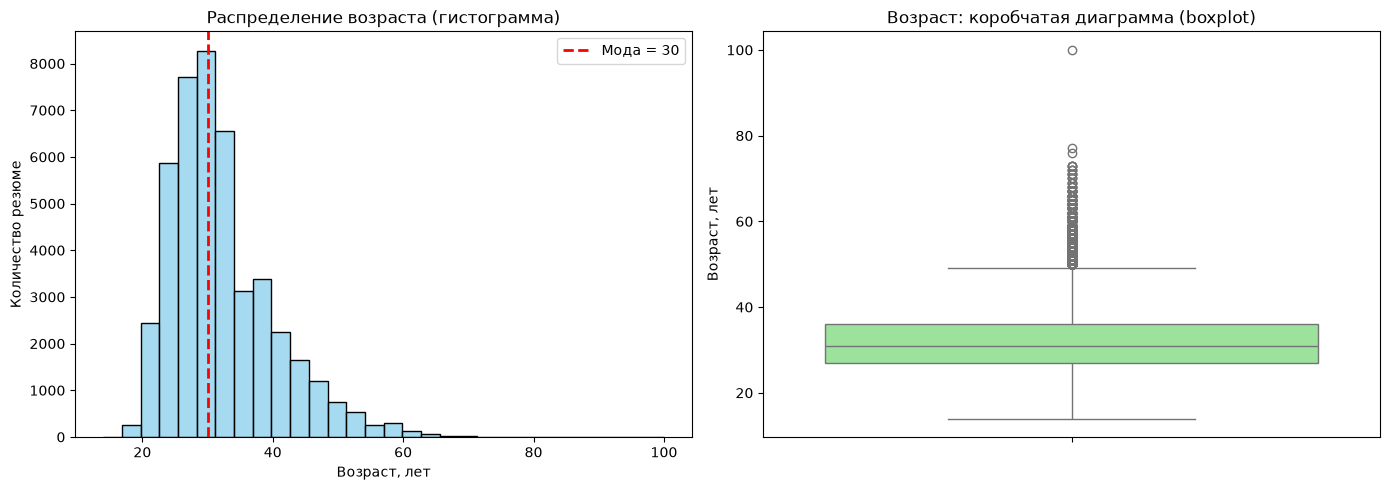

Мода распределения возраста: 30 лет

Предельные значения: от 14 до 100 лет.
Интервал большинства (межквартильный размах): от 27.0 до 36.0 лет.
Границы выбросов по IQR: от 13.5 до 49.5

Количество аномальных значений: 1774
Примеры аномальных возрастов: <IntegerArray>
[ 60,  59,  53,  54,  62,  72,  61,  50,  58,  57,  52,  56,  51,  71,  63,
  55,  64,  68,  73,  66,  65,  77,  67,  69,  76,  70, 100]
Length: 27, dtype: Int64


In [14]:
# ваш код здесь

# Задание 4.1 Чему равно модальное значение возраста соискателей?

# Мода распределения 
mode_age = df["Возраст"].mode()[0]

# Предельные значения и интервал большинства 
min_age = df["Возраст"].min()
max_age = df["Возраст"].max()
q1 = df["Возраст"].quantile(0.25)
q3 = df["Возраст"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr


# Визуализация
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(df["Возраст"], bins=30, kde=False, ax=axs[0], color="skyblue", edgecolor="black")
axs[0].axvline(mode_age, color="red", linestyle="--", linewidth=2, label=f"Мода = {mode_age}")
axs[0].set_title("Распределение возраста (гистограмма)")
axs[0].set_xlabel("Возраст, лет")
axs[0].set_ylabel("Количество резюме")
axs[0].legend()

# Коробчатая диаграмма
sns.boxplot(y=df["Возраст"], ax=axs[1], color="lightgreen")
axs[1].set_title("Возраст: коробчатая диаграмма (boxplot)")
axs[1].set_ylabel("Возраст, лет")

plt.tight_layout()
plt.show()

# Plotly
fig_hist = px.histogram(df, x="Возраст", nbins=30, title="Распределение возраста (Plotly)",
                        labels={"Возраст": "Возраст, лет", "count": "Количество резюме"})
fig_hist.add_vline(x=mode_age, line_dash="dash", line_color="red", annotation_text=f"Мода={mode_age}", annotation_position="top left")
fig_hist.update_layout(xaxis_title="Возраст, лет", yaxis_title="Количество резюме")
fig_hist.show()


print(f"Мода распределения возраста: {mode_age} лет")
print(f"\nПредельные значения: от {min_age} до {max_age} лет.")
print(f"Интервал большинства (межквартильный размах): от {q1} до {q3} лет.")
print(f"Границы выбросов по IQR: от {lower_bound:.1f} до {upper_bound:.1f}")

# Поиск аномалий
anomalies = df[(df["Возраст"] < lower_bound) | (df["Возраст"] > upper_bound)]
print(f"\nКоличество аномальных значений: {len(anomalies)}")
if len(anomalies) > 0:
    print("Примеры аномальных возрастов:", anomalies["Возраст"].unique())


ваши выводы по графику здесь

Мода распределения - 30 лет.   
Предельные значения признака - от 14 до 100 лет.  100 лет - явная аномалия.  
Интервал большинства соискателей - примерно от 27 до 36 лет.  

2. Постройте распределение признака **"Опыт работы (месяц)"**. Опишите данное распределение, отвечая на следующие вопросы: чему равна мода распределения, каковы предельные значения признака, в каком примерном интервале находится опыт работы большинства соискателей? Есть ли аномалии для признака опыта работы, какие значения вы бы причислили к их числу?
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*

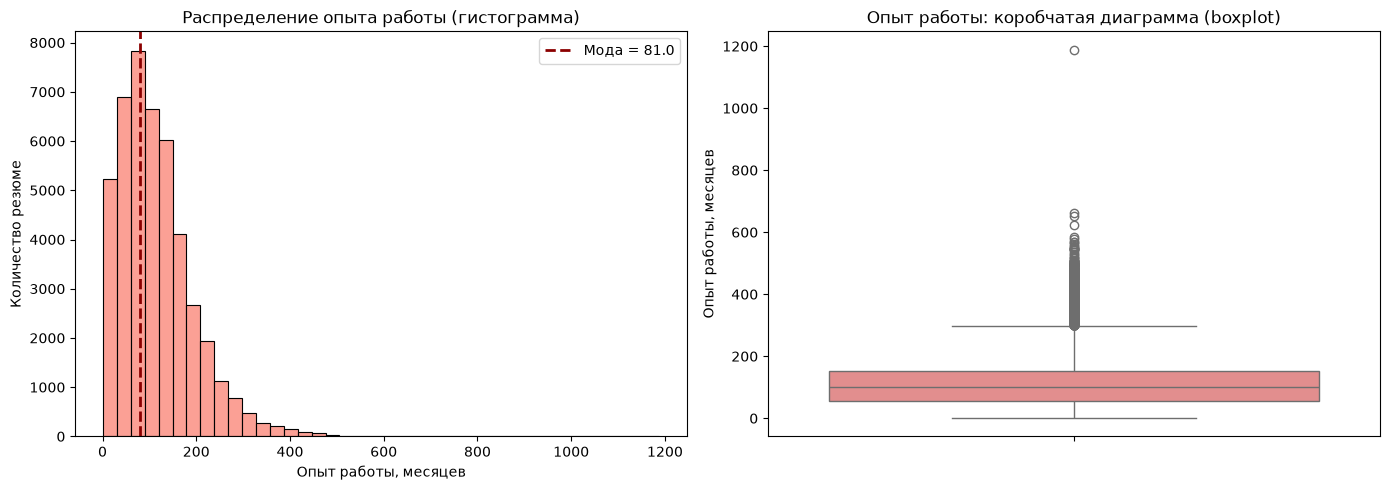

Мода распределения опыта работы: 81.0 месяцев

Предельные значения опыта: от 1.0 до 1188.0 месяцев.
Интервал большинства (межквартильный размах): от 57.0 до 154.0 месяцев.
Границы выбросов: от -88.5 до 299.5

Количество аномальных значений: 1276
Примеры аномальных значений опыта (месяцы): [np.float64(300.0), np.float64(301.0), np.float64(302.0), np.float64(303.0), np.float64(304.0), np.float64(305.0), np.float64(306.0), np.float64(307.0), np.float64(308.0), np.float64(309.0), np.float64(310.0), np.float64(311.0), np.float64(312.0), np.float64(313.0), np.float64(314.0), np.float64(315.0), np.float64(316.0), np.float64(317.0), np.float64(318.0), np.float64(319.0), np.float64(320.0), np.float64(321.0), np.float64(322.0), np.float64(323.0), np.float64(324.0), np.float64(325.0), np.float64(326.0), np.float64(327.0), np.float64(328.0), np.float64(329.0), np.float64(330.0), np.float64(331.0), np.float64(332.0), np.float64(333.0), np.float64(334.0), np.float64(335.0), np.float64(336.0), np.flo

In [15]:
# ваш код здесь

# Задание 4.2 Чему равен максимальный опыт работы (в месяцах)?

# Мода распределения
mode_exp = df["Опыт работы (месяц)"].mode()[0]


# Предельные значения и интервал большинства 
min_exp = df["Опыт работы (месяц)"].min()
max_exp = df["Опыт работы (месяц)"].max()
q1_exp = df["Опыт работы (месяц)"].quantile(0.25)
q3_exp = df["Опыт работы (месяц)"].quantile(0.75)
iqr_exp = q3_exp - q1_exp
lower_bound_exp = q1_exp - 1.5 * iqr_exp
upper_bound_exp = q3_exp + 1.5 * iqr_exp



# Поиск аномалий 
anomalies_exp = df[(df["Опыт работы (месяц)"] < lower_bound_exp) | (df["Опыт работы (месяц)"] > upper_bound_exp)]


# Визуализация
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
sns.histplot(df["Опыт работы (месяц)"], bins=40, kde=False, ax=axs[0], color="salmon", edgecolor="black")
axs[0].axvline(mode_exp, color="darkred", linestyle="--", linewidth=2, label=f"Мода = {mode_exp}")
axs[0].set_title("Распределение опыта работы (гистограмма)")
axs[0].set_xlabel("Опыт работы, месяцев")
axs[0].set_ylabel("Количество резюме")
axs[0].legend()

# Коробчатая диаграмма
sns.boxplot(y=df["Опыт работы (месяц)"], ax=axs[1], color="lightcoral")
axs[1].set_title("Опыт работы: коробчатая диаграмма (boxplot)")
axs[1].set_ylabel("Опыт работы, месяцев")

plt.tight_layout()
plt.show()

# Plotly
fig_hist_exp = px.histogram(df, x="Опыт работы (месяц)", nbins=40, title="Распределение опыта работы (Plotly)",
                            labels={"Опыт работы (месяц)": "Опыт работы, месяцев", "count": "Количество резюме"})
fig_hist_exp.add_vline(x=mode_exp, line_dash="dash", line_color="darkred",
                       annotation_text=f"Мода={mode_exp}", annotation_position="top left")
fig_hist_exp.update_layout(xaxis_title="Опыт работы, месяцев", yaxis_title="Количество резюме")
fig_hist_exp.show()

print(f"Мода распределения опыта работы: {mode_exp} месяцев")
print(f"\nПредельные значения опыта: от {min_exp} до {max_exp} месяцев.")
print(f"Интервал большинства (межквартильный размах): от {q1_exp} до {q3_exp} месяцев.")
print(f"Границы выбросов: от {lower_bound_exp:.1f} до {upper_bound_exp:.1f}")
print(f"\nКоличество аномальных значений: {len(anomalies_exp)}")
if len(anomalies_exp) > 0:
    print("Примеры аномальных значений опыта (месяцы):", sorted(anomalies_exp["Опыт работы (месяц)"].unique()))


ваши выводы здесь

Мода распределения - 81 месяц (это около 6,5 года). Такой опыт оказался у наибольшего числа соискателей.  
Предельные значения - от 1 до 1188 месяцев. 1188/12 примерно 99 лет - аномалия.
Интервал большинства соискателей - от 57 до 154 месяцев.
Центральная половина резюме лежит в этом диапазоне, медиана около 100 месяцев.


3. Постройте распределение признака **"ЗП (руб)"**. Опишите данное распределение, отвечая на следующие вопросы: каковы предельные значения признака, в каком примерном интервале находится заработная плата большинства соискателей? Есть ли аномалии для признака возраста? Обратите внимание на гигантские размеры желаемой заработной платы.
*Совет: постройте гистограмму и коробчатую диаграмму рядом.*


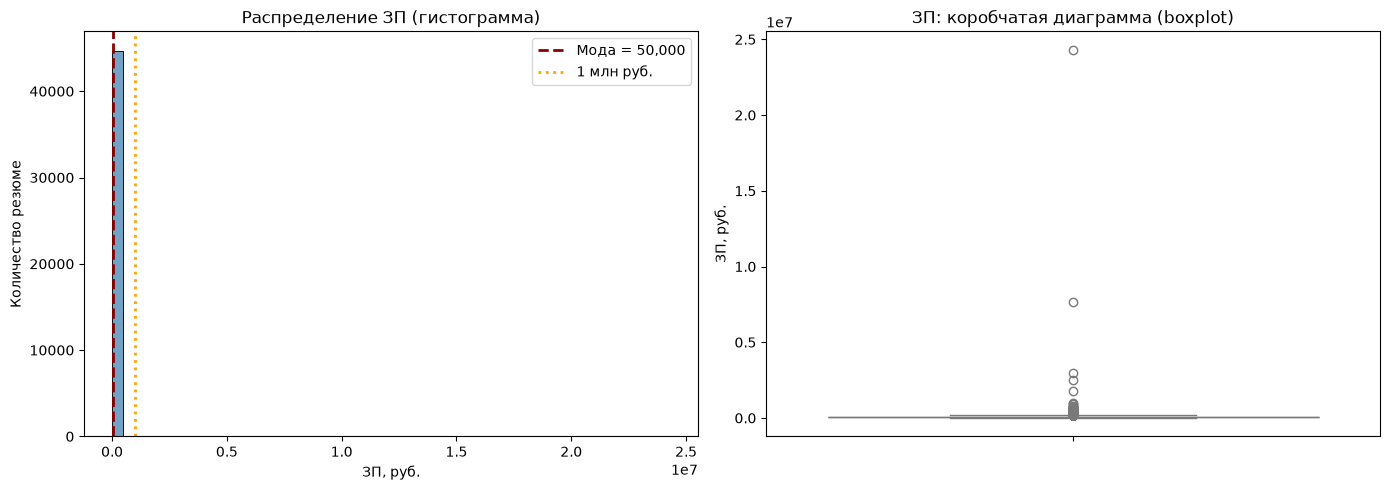

Мода ЗП: 50,000 руб.
Предельные значения: от 1 до 24,304,876 руб.
Интервал большинства (IQR): от 37,082 до 95,000 руб.
Верхняя граница выбросов (IQR): 181,877 руб.
Соискателей с ЗП > 1 млн руб.: 5


In [16]:
# ваш код здесь

# Задание 4.3 Определите по графику, сколько соискателей требуют заработную плату выше 1 миллиона рублей.

# Статистика
mode_zp = df["ЗП (руб)"].mode()[0]
min_zp = df["ЗП (руб)"].min()
max_zp = df["ЗП (руб)"].max()
q1_zp = df["ЗП (руб)"].quantile(0.25)
q3_zp = df["ЗП (руб)"].quantile(0.75)
iqr_zp = q3_zp - q1_zp
upper_bound_zp = q3_zp + 1.5 * iqr_zp

count_over_1m = (df["ЗП (руб)"] > 1_000_000).sum()

# Визуализация
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["ЗП (руб)"], bins=50, kde=False, ax=axs[0], color="steelblue", edgecolor="black")
axs[0].axvline(mode_zp, color="darkred", linestyle="--", linewidth=2, label=f"Мода = {mode_zp:,.0f}")
axs[0].axvline(1_000_000, color="orange", linestyle=":", linewidth=2, label="1 млн руб.")
axs[0].set_title("Распределение ЗП (гистограмма)")
axs[0].set_xlabel("ЗП, руб.")
axs[0].set_ylabel("Количество резюме")
axs[0].legend()

sns.boxplot(y=df["ЗП (руб)"], ax=axs[1], color="lightblue")
axs[1].set_title("ЗП: коробчатая диаграмма (boxplot)")
axs[1].set_ylabel("ЗП, руб.")

plt.tight_layout()
plt.show()

print(f"Мода ЗП: {mode_zp:,.0f} руб.")
print(f"Предельные значения: от {min_zp:,.0f} до {max_zp:,.0f} руб.")
print(f"Интервал большинства (IQR): от {q1_zp:,.0f} до {q3_zp:,.0f} руб.")
print(f"Верхняя граница выбросов (IQR): {upper_bound_zp:,.0f} руб.")
print(f"Соискателей с ЗП > 1 млн руб.: {count_over_1m}")



ваши выводы здесь

Предельные значения - от 1 до 24 304 876 рублей. 1 и 24 304 876  могут быть аномалиями.  
Интервал большинства соискателей - примерно от 37 000 до 95 000 рублей.  
Мода - 50 000 рублей.



4. Постройте диаграмму, которая показывает зависимость **медианной** желаемой заработной платы (**"ЗП (руб)"**) от уровня образования (**"Образование"**). Используйте для диаграммы данные о резюме, где желаемая заработная плата меньше 1 млн рублей.
*Сделайте выводы по представленной диаграмме: для каких уровней образования наблюдаются наибольшие и наименьшие уровни желаемой заработной платы? Как вы считаете, важен ли признак уровня образования при прогнозировании заработной платы?*

In [17]:
# ваш код здесь

# Задание 4.4 Какая категория образования оплачивается выше всех по медианному показателю?
import plotly.express as px

# Фильтруем данные желаемая ЗП меньше 1 млн руб.
df_filtered = df[df["ЗП (руб)"] < 1_000_000]

# Считаем медианную ЗП по уровням образования
median_by_edu = (
    df_filtered.groupby("Образование")["ЗП (руб)"].median()
    .sort_values(ascending=False)
)

# Диаграмма
fig = px.bar(
    x=median_by_edu.index,
    y=median_by_edu.values,
    title="Медианная желаемая ЗП по уровням образования",
    labels={"x": "Уровень образования", "y": "Медианная ЗП, руб."},
    text_auto=True
)
fig.show()

print("Медианная ЗП по уровням образования:")
print(median_by_edu.round(0).astype(int))


Медианная ЗП по уровням образования:
Образование
высшее                 60000
неоконченное высшее    50000
среднее                40000
среднее специальное    40000
Name: ЗП (руб), dtype: int64


ваши выводы здесь

Наибольшая медианная желаемая ЗП - у соискателей с высшим образованием: 60 000 рублей.  
Наименьшие медианные значения - у категорий "среднее" и "среднее специальное": по 40 000 рублей.   
Неоконченное высшее занимает промежуточное положение: 50 000 рублей.  

Важен ли признак образования при прогнозировании ЗП?  
Да, видна логическая связь между уровнями образования и желаемой ЗП.

5. Постройте диаграмму, которая показывает распределение желаемой заработной платы (**"ЗП (руб)"**) в зависимости от города (**"Город"**). Используйте для диаграммы данные о резюме, где желая заработная плата меньше 1 млн рублей.
*Сделайте выводы по полученной диаграмме: как соотносятся медианные уровни желаемой заработной платы и их размах в городах? Как вы считаете, важен ли признак города при прогнозировании заработной платы?*

In [18]:
# ваш код здесь

# Задание 4.5 В каком городе (категории городов) зафиксирован наибольший показатель желаемой заработной платы (~924 тысячи рублей)?

# Фильтруем данные желаемая ЗП меньше 1 млн руб.
df_filtered = df[df["ЗП (руб)"] < 1_000_000]

# Строим boxplot
fig = px.box(
    df_filtered,
    x="Город",
    y="ЗП (руб)",
    title="Распределение желаемой ЗП по городам (ЗП < 1 млн руб.)",
    labels={"Город": "Город", "ЗП (руб)": "Желаемая ЗП, руб."},
    points="outliers"  # показываем выбросы отдельно
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()
# Считаем медиану
city_stats = (
    df_filtered.groupby("Город")["ЗП (руб)"]
    .agg(["median", "min", "max"])
    .reset_index()
    .sort_values("median", ascending=False)
)

print(city_stats.to_string(index=False))

           Город  median  min      max
          Москва 85000.0  1.0 900000.0
 Санкт-Петербург 60000.0  1.0 645171.0
город-миллионник 40000.0  1.0 511681.6
          другие 40000.0  1.0 923983.0


ваши выводы здесь

Наибольшая медиана - в Москве: 85 000 рублей.
Наименьшие медианы - в городах-миллионниках и категории "другие": по 40 000 рублей. 

Как вы считаете, важен ли признак города при прогнозировании заработной платы?  
Да, важен, потому что медианы между городами различаются более чем в два раза (40 000 против 85 000).


6. Постройте **многоуровневую столбчатую диаграмму**, которая показывает зависимость медианной заработной платы (**"ЗП (руб)"**) от признаков **"Готовность к переезду"** и **"Готовность к командировкам"**. Проанализируйте график, сравнив уровень заработной платы в категориях.

In [19]:
# ваш код здесь

# Задание 4.6 Чему равна желаемая медианная заработная плата соискателей, готовых и к переезду, и к командировкам?
# Ответ приведите в тысячах, округлив до целого (например, 45).


# Считаем медианную ЗП по комбинациям признаков
median_ready = df.groupby(["Готовность к переезду", "Готовность к командировкам"])["ЗП (руб)"].median()

print("Медианная ЗП по комбинациям признаков:")
print(median_ready.round(0).astype(int))

# Многоуровневая столбчатая диаграмма
fig = px.bar(
    df.groupby(["Готовность к переезду", "Готовность к командировкам"], as_index=False)["ЗП (руб)"].median(),
    x="Готовность к переезду",
    y="ЗП (руб)",
    color="Готовность к командировкам",
    barmode="group",
    title="Медианная ЗП в зависимости от готовности к переезду и командировкам",
    labels={"ЗП (руб)": "Медианная ЗП, руб.", "Готовность к переезду": "Готовность к переезду",
            "Готовность к командировкам": "Готовность к командировкам"},
    text_auto=True
)
fig.show()

target = median_ready.loc[True, True]  # если True/False; иначе loc["да", "да"]
print(f"Ответ: {round(target / 1000)} тыс. руб.")


Медианная ЗП по комбинациям признаков:
Готовность к переезду  Готовность к командировкам
False                  False                         40000
                       True                          60000
True                   False                         50000
                       True                          65849
Name: ЗП (руб), dtype: int64


Ответ: 66 тыс. руб.


In [20]:
# ваши выводы здесь

Наибольшая медианная ЗП - у соискателей, готовых и к переезду, и к командировкам: примерно 65 849 рублей, то есть 66 тысяч. 

7. Постройте сводную таблицу, иллюстрирующую зависимость **медианной** желаемой заработной платы от возраста (**"Возраст"**) и образования (**"Образование"**). На полученной сводной таблице постройте **тепловую карту**. Проанализируйте тепловую карту, сравнив показатели внутри групп.

In [21]:
# ваш код здесь

# Задание 4.7 Для какой категории образования наблюдается самый быстрый карьерный рост (то есть интенсивность роста заработной платы наибольшая)?

# 1. Подготовка данных
df_eda = df.copy()
df_eda = df_eda.dropna(subset=["Возраст", "Образование", "ЗП (руб)"])
df_eda = df_eda[np.isfinite(df_eda["ЗП (руб)"])]

# 2. Сводная таблица
pivot_salaries = df_eda.pivot_table(
    index="Возраст",
    columns="Образование",
    values="ЗП (руб)",
    aggfunc="median"
)

print("Сводная таблица (медианная ЗП):")
print(pivot_salaries)

# Тепловая карта
fig = px.imshow(
    pivot_salaries,
    title="Медианная желаемая ЗП: возраст и образование",
    labels=dict(x="Образование", y="Возраст", color="Медианная ЗП, руб."),
    aspect="auto",
    text_auto=".0f",
    color_continuous_scale="Viridis"
)
fig.update_layout(xaxis_tickangle=-45)
fig.show()



Сводная таблица (медианная ЗП):
Образование     высшее  неоконченное высшее  среднее  среднее специальное
Возраст                                                                  
14            60000.00                  NaN      NaN                  NaN
15                 NaN                  NaN  10000.0               2000.0
16           122582.49                  NaN      NaN              30000.0
17            90075.50              80000.0  44000.0              25000.0
18            30000.00              25000.0  35000.0              25151.0
...                ...                  ...      ...                  ...
72            75000.00                  NaN      NaN                  NaN
73            62500.00                  NaN      NaN                  NaN
76            45000.00                  NaN      NaN                  NaN
77            90000.00                  NaN      NaN                  NaN
100                NaN                  NaN      NaN              60000.0

[63 r

ваши выводы здесь

Желаемая ЗП растет с возрастом во всех группах, но быстрее всего - у соискателей с высшим образованием, их медианные запросы к зрелому возрасту заметно опережают остальные категории. Для «среднего» образование рост практически отсутствует.

8. Постройте **диаграмму рассеяния**, показывающую зависимость опыта работы (**"Опыт работы (месяц)"**) от возраста (**"Возраст"**). Опыт работы переведите из месяцев в года, чтобы признаки были в едином масштабе. Постройте на графике дополнительно прямую, проходящую через точки (0, 0) и (100, 100). Данная прямая соответствует значениям, когда опыт работы равен возрасту человека. Точки, лежащие на этой прямой и выше нее - аномалии в наших данных (опыт работы больше либо равен возрасту соискателя)

Количество аномалий (опыт >= возраст): 7


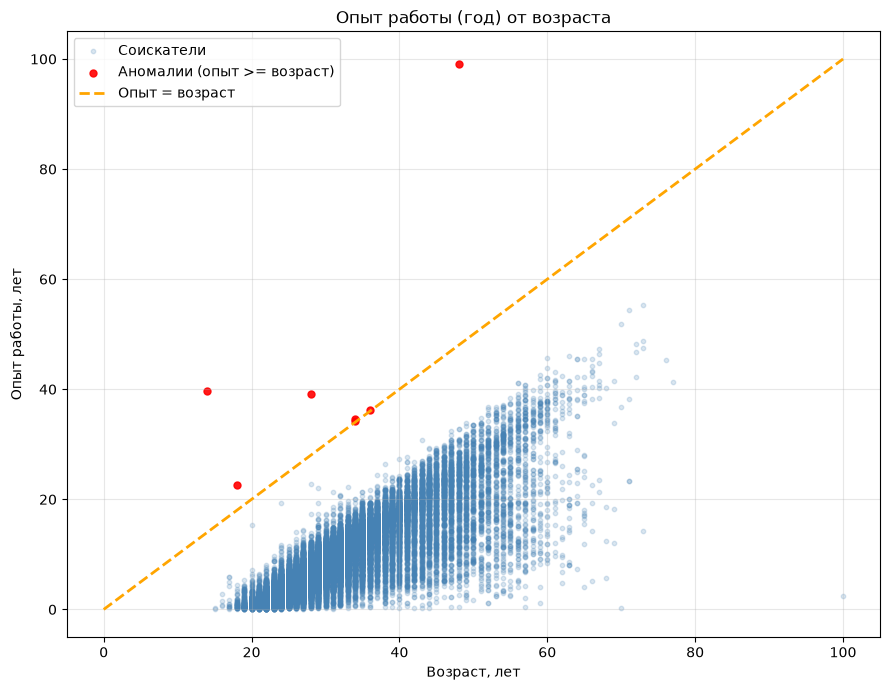

In [22]:
# Задание 4.8 Диаграмма рассеяния: опыт работы (в годах) от возраста

# Переводим опыт работы из месяцев в годы
df_scatter = df.copy()
df_scatter["Опыт работы (год)"] = df_scatter["Опыт работы (месяц)"] / 12

# Аномалии опыт больше либо равен возрасту 
anomalies_mask = df_scatter["Опыт работы (год)"] >= df_scatter["Возраст"]
n_anomalies = anomalies_mask.sum()
print(f"Количество аномалий (опыт >= возраст): {n_anomalies}")

# Статичная диаграмма рассеяния
fig, ax = plt.subplots(figsize=(9, 7))

# Обычные точки
normal = df_scatter[~anomalies_mask]
ax.scatter(normal["Возраст"], normal["Опыт работы (год)"],
           alpha=0.2, s=10, color="steelblue", label="Соискатели")

# Аномалии  поверх другим цветом
anomalies_pts = df_scatter[anomalies_mask]
ax.scatter(anomalies_pts["Возраст"], anomalies_pts["Опыт работы (год)"],
           alpha=0.9, s=25, color="red", label="Аномалии (опыт >= возраст)")

# Прямая (0, 0) - (100, 100): опыт равен возрасту
ax.plot([0, 100], [0, 100], color="orange", linestyle="--", linewidth=2,
        label="Опыт = возраст")

ax.set_title("Опыт работы (год) от возраста")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Опыт работы, лет")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plotly
fig_scatter = px.scatter(
    df_scatter,
    x="Возраст",
    y="Опыт работы (год)",
    color=anomalies_mask.map({False: "Соискатели", True: "Аномалии"}),
    color_discrete_map={"Соискатели": "rgba(70, 130, 180, 0.2)",
                        "Аномалии": "red"},
    title="Опыт работы (год) от возраста",
    labels={"Возраст": "Возраст, лет", "Опыт работы (год)": "Опыт работы, лет"},
    opacity=0.3
)

# Прямая (0, 0) - (100, 100)
x_line = [0, 100]
y_line = [0, 100]
fig_scatter.add_scatter(x=x_line, y=y_line, mode="lines",
                        line=dict(color="orange", dash="dash", width=2),
                        name="Опыт = возраст")

fig_scatter.update_layout(
    xaxis_title="Возраст, лет",
    yaxis_title="Опыт работы, лет",
    legend_title="Категория"
)
fig_scatter.show()


In [23]:
# Оценка карьерного роста: двумя способами

# Способ 1: прирост медианы между окнами 22-26 и 55-60 лет
rows = []
for edu, sub in df_eda.groupby("Образование"):
    start = sub[sub["Возраст"].between(22, 26)]
    end = sub[sub["Возраст"].between(55, 60)]
    rows.append({
        "Образование": edu,
        "n старт": len(start),
        "медиана старт": start["ЗП (руб)"].median(),
        "n финиш": len(end),
        "медиана финиш": end["ЗП (руб)"].median(),
        "прирост": end["ЗП (руб)"].median() - start["ЗП (руб)"].median(),
    })
growth = pd.DataFrame(rows)
print("Прирост медианной ЗП (22-26 -> 55-60 лет):")
print(growth.round(0))

# Способ 2: наклон линии тренда медианы по всем возрастам
slopes = {}
for edu, sub in df_eda.groupby("Образование"):
    by_age = sub.groupby("Возраст")["ЗП (руб)"].median().dropna()
    if len(by_age) >= 2:
        slopes[edu] = np.polyfit(by_age.index, by_age.values, 1)[0]

slope_series = pd.Series(slopes).sort_values(ascending=False)
print("\nНаклон тренда медианной ЗП, руб. за год:")
print(slope_series.round(0))
print("\nСамый быстрый рост по наклону тренда:", slope_series.idxmax())


Прирост медианной ЗП (22-26 -> 55-60 лет):
           Образование  n старт  медиана старт  n финиш  медиана финиш  \
0               высшее     6239        50000.0      539        65349.0   
1  неоконченное высшее     1287        40000.0       19        70000.0   
2              среднее      121        40000.0        5        30000.0   
3  среднее специальное     1877        35000.0       42        41219.0   

   прирост  
0  15349.0  
1  30000.0  
2 -10000.0  
3   6219.0  

Наклон тренда медианной ЗП, руб. за год:
неоконченное высшее    479.0
среднее специальное    357.0
высшее                 299.0
среднее                298.0
dtype: float64

Самый быстрый рост по наклону тренда: неоконченное высшее


Аномалии - 7 соискателей с опытом, большим либо равным возрасту (среди них 15-летний с 40 годами стажа и 45-летний со 99 годами стажа)

**Дополнительные баллы**

Для получения 2 дополнительных баллов по разведывательному анализу постройте еще два любых содержательных графика или диаграммы, которые помогут проиллюстрировать влияние признаков/взаимосвязь между признаками/распределения признаков. Приведите выводы по ним. Желательно, чтобы в анализе участвовали признаки, которые мы создавали ранее в разделе "Преобразование данных".


In [24]:
# ваш код здесь

# распределение ЗП в зависимости от пола
fig = px.box(
    df,
    x="Пол",
    y="ЗП (руб)",
    color="Пол",
    points="outliers",
    title="Распределение ЗП (руб) в зависимости от пола",
    labels={"Пол": "Пол", "ЗП (руб)": "Желаемая ЗП, руб."},
    height=500
)
fig.show()

print(df.groupby("Пол")["ЗП (руб)"].describe().round(0))

       count     mean       std   min      25%      50%       75%         max
Пол                                                                          
Ж     8533.0  60081.0   46376.0  25.0  30000.0  48000.0   70000.0   1000000.0
М    36211.0  80410.0  149151.0   1.0  40000.0  60000.0  100000.0  24304876.0


In [25]:
# Дополнительный график 2, медианная ЗП в зависимости от графика работы

# Находим столбцы-флаги автоматически: ищем слова про график работы и оставляем только бинарные столбцы (значения 0/1)
keywords = ["график", "день", "вахт", "удален", "сменн", "гибк"]
candidates = [c for c in df.columns
              if c != "График" and any(k in c.lower() for k in keywords)]
schedule_flags = [c for c in candidates
                  if df[c].dropna().isin([0, 1]).all()]

print("Найдены флаги:", schedule_flags)

# Собираем статистику
rows = []
for flag in schedule_flags:
    rows.append({
        "График": flag,
        "Медианная ЗП": df.loc[df[flag] == 1, "ЗП (руб)"].median(),
        "Число резюме": int(df[flag].sum())
    })
schedule_stats = pd.DataFrame(rows).sort_values("Медианная ЗП", ascending=False)
print(schedule_stats)

# Столбчатая диаграмма
fig = px.bar(
    schedule_stats,
    x="График",
    y="Медианная ЗП",
    color="Медианная ЗП",
    text_auto=True,
    title="Медианная ЗП в зависимости от графика работы",
    labels={"Медианная ЗП": "Медианная ЗП, руб."},
    height=500
)
fig.show()


Найдены флаги: ['График_полный_день', 'График_сменный_график', 'График_гибкий_график', 'График_удаленная_работа', 'График_вахтовый_метод']
                    График  Медианная ЗП  Число резюме
0       График_полный_день       60000.0         41716
3  График_удаленная_работа       60000.0         15022
2     График_гибкий_график       55000.0         15584
1    График_сменный_график       50000.0         12725
4    График_вахтовый_метод       50000.0          3084


График 1.  
Медиана ЗП у мужчин выше, чем у женщин: 60 000 против 48 000 руб. Разрыв составляет 12 000 руб. (25%). Средние значения различаются еще сильнее: 80 410 у мужчин против 60 081 у женщин. У мужчин заметно шире разброс (std 149 151 против 46 376) и встречаются более высокие максимумы запросов.  
Часть экстремальных значений - выбросы.

График 2.  
Самые высокие медианные запросы у соискателей с полным днем и удаленной работой - по 60 000 руб.


# Очистка данных

1. Начнем с дубликатов в наших данных. Найдите **полные дубликаты** в таблице с резюме и удалите их. 

In [26]:
# ваш код здесь

# Задание 5.1 Начнём с дубликатов в наших данных. Найдите полные дубликаты в таблице с резюме и удалите их.
# Считаем количество полных дубликатов
dup_count = df.duplicated().sum()
print(f"Полных дубликатов: {dup_count}")

# Удаляем дубликаты, оставляя первое вхождение
df = df.drop_duplicates()

# Проверяем размер таблицы после удаления
print(f"Строк до удаления: {len(df) + dup_count}")
print(f"Строк после удаления: {len(df)}")

Полных дубликатов: 161
Строк до удаления: 44744
Строк после удаления: 44583


2. Займемся пропусками. Выведите информацию **о числе пропусков** в столбцах. 

In [27]:
# ваш код здесь

# Задание 5.2 Займёмся пропусками. Выведите информацию о числе пропусков в столбцах. Сколько пропусков в столбце «Опыт работы (месяц)»?
# Выводим информацию о числе пропусков во всех столбцах
print(df.isna().sum())

# Отдельно считаем пропуски в столбце "Опыт работы (месяц)"
missing_exp = df["Опыт работы (месяц)"].isna().sum()
print(f"\nПропусков в столбце 'Опыт работы (месяц)': {missing_exp}")


Ищет работу на должность:            0
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
Обновление резюме                    0
Авто                                 0
Образование                          0
Пол                                  0
Возраст                              0
Опыт работы (месяц)                168
Город                                0
Готовность к переезду                0
Готовность к командировкам           0
Занятость_полная_занятость           0
Занятость_частичная_занятость        0
Занятость_проектная_работа           0
Занятость_волонтерство               0
Занятость_стажировка                 0
График_полный_день                   0
График_сменный_график                0
График_гибкий_график                 0
График_удаленная_работа              0
График_вахтовый_метод                0
ЗП (руб)                             0
dtype: int64

Пропусков в столбце 'Опыт работы (месяц)': 168


3. Итак, у нас есть пропуски в 3ех столбцах: **"Опыт работы (месяц)"**, **"Последнее/нынешнее место работы"**, **"Последняя/нынешняя должность"**. Поступим следующим образом: удалите строки, где есть пропуск в столбцах с местом работы и должностью. Пропуски в столбце с опытом работы заполните **медианным** значением.

In [28]:
# ваш код здесь
# Задание 5.3 Чему равно результирующее среднее значение в столбце «Опыт работы (месяц)» после заполнения пропусков? Ответ округлите до целых.
# Удаляем строки, где есть пропуск в столбцах с местом работы и должностью
df = df.dropna(subset=["Последнее/нынешнее место работы", "Последняя/нынешняя должность"])

# Заполняем пропуски в опыте работы медианным значением
median_exp = df["Опыт работы (месяц)"].median()
df["Опыт работы (месяц)"] = df["Опыт работы (месяц)"].fillna(median_exp)
print(f"Медиана опыта работы: {median_exp}")

# Среднее значение после заполнения пропусков
print(f"Среднее значение опыта работы: {round(df["Опыт работы (месяц)"].mean())}")

Медиана опыта работы: 100.0
Среднее значение опыта работы: 114


4. Мы добрались до ликвидации выбросов. Сначала очистим данные вручную. Удалите резюме, в которых указана заработная плата либо выше 1 млн. рублей, либо ниже 1 тыс. рублей.

In [29]:
# ваш код здесь

# Считаем количество выбросов ДО удаления
outliers_count = ((df["ЗП (руб)"] > 1_000_000) | (df["ЗП (руб)"] < 1_000)).sum()

# Задание 5.4 Сколько выбросов вы нашли?
print(f"Найдено выбросов (ЗП < 1 тыс. или > 1 млн руб.): {outliers_count}")

# Удаляем резюме с выбросами по ЗП
df = df[~((df["ЗП (руб)"] > 1_000_000) | (df["ЗП (руб)"] < 1_000))]

print(f"Строк после удаления выбросов: {len(df)}")

Найдено выбросов (ЗП < 1 тыс. или > 1 млн руб.): 89
Строк после удаления выбросов: 44492


5. В процессе разведывательного анализа мы обнаружили резюме, в которых **опыт работы в годах превышал возраст соискателя**. Найдите такие резюме и удалите их из данных


In [30]:
# ваш код здесь

# Задание 5.5 Сколько выбросов вы нашли?
df = df.dropna(subset=["Возраст", "Опыт работы (месяц)"])

# Считаем выбросы
outliers_mask = (df["Опыт работы (месяц)"] / 12) > df["Возраст"]
outliers_count = outliers_mask.sum()

print(f"Найдено выбросов (опыт в годах > возраста): {outliers_count}")

# Удаляем строки с выбросами
df = df[~outliers_mask]

print(f"Строк после удаления выбросов: {len(df)}")
print("\nПроверка: максимальный опыт в годах и максимальный возраст:")
print((df["Опыт работы (месяц)"] / 12).max(), df["Возраст"].max())

Найдено выбросов (опыт в годах > возраста): 7
Строк после удаления выбросов: 44485

Проверка: максимальный опыт в годах и максимальный возраст:
55.25 100


6. В результате анализа мы обнаружили потенциальные выбросы в признаке **"Возраст"**. Это оказались резюме людей чересчур преклонного возраста для поиска работы. Попробуйте построить распределение признака в **логарифмическом масштабе**. Добавьте к графику линии, отображающие **среднее и границы интервала метода трех сигм**. Напомним, сделать это можно с помощью метода axvline. Например, для построение линии среднего будет иметь вид:

`histplot.axvline(log_age.mean(), color='k', lw=2)`

В какую сторону асимметрично логарифмическое распределение? Напишите об этом в комментарии к графику.
Найдите выбросы с помощью метода z-отклонения и удалите их из данных, используйте логарифмический масштаб. Давайте сделаем послабление на **1 сигму** (возьмите 4 сигмы) в **правую сторону**.

Выведите таблицу с полученными выбросами и оцените, с каким возрастом соискатели попадают под категорию выбросов?

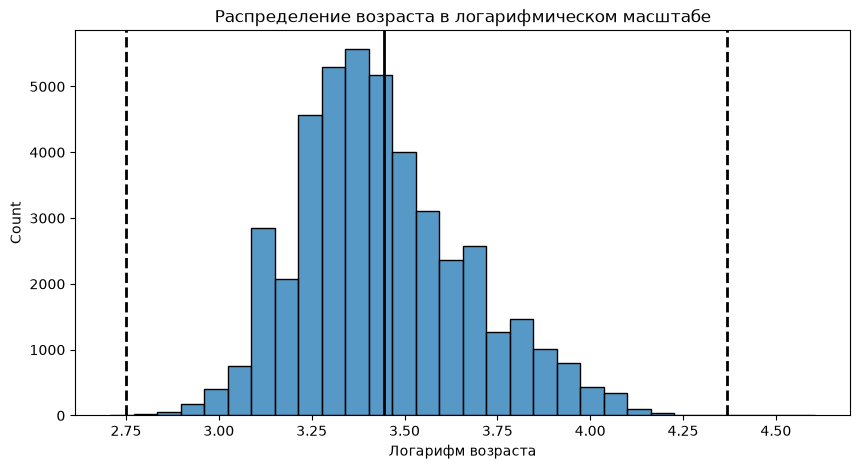

Найдено выбросов методом z-отклонений: 3
            Ищет работу на должность: Последнее/нынешнее место работы  \
31137  Менеджер по работе с клиентами           ООО "ФёрстКэшКомпани"   
32950                 Тестировщик игр                        OOO ЖМЫХ   
33654            Frontend-разработчик                       Freelance   

         Последняя/нынешняя должность Обновление резюме        Авто  \
31137  Менеджер по работе с клиентами        2019-04-06  Не указано   
32950                  Тестировщик ПО        2019-04-09  Не указано   
33654            Frontend-разработчик        2019-04-19  Не указано   

               Образование Пол  Возраст  Опыт работы (месяц)            Город  \
31137              среднее   М       15                  2.0  Санкт-Петербург   
32950  среднее специальное   М       15                  3.0           другие   
33654  среднее специальное   М      100                 30.0  Санкт-Петербург   

       ...  Занятость_частичная_занятость  Занятость_про

In [31]:
# ваш код здесь

# Задание 5.6 Сколько выбросов вы нашли с помощью метода z-отклонений?
# Логарифмируем возраст
log_age = np.log(df["Возраст"])

# Строим распределение в логарифмическом масштабе
fig, ax = plt.subplots(figsize=(10, 5))
log_age_hist = sns.histplot(log_age, bins=30, ax=ax)

# Линии среднего и границ интервала метода трех сигм
log_age_hist.axvline(log_age.mean(), color="k", lw=2)
log_age_hist.axvline(log_age.mean() - 3 * log_age.std(), color="k", ls="--", lw=2)
log_age_hist.axvline(log_age.mean() + 4 * log_age.std(), color="k", ls="--", lw=2)

plt.title("Распределение возраста в логарифмическом масштабе")
plt.xlabel("Логарифм возраста")
plt.show()

# Метод z-отклонений в логарифмическом масштабе: границы — среднее минус 3 сигмы слева и среднее плюс 4 сигмы справа (послабление на 1 сигму)
z_left = log_age.mean() - 3 * log_age.std()
z_right = log_age.mean() + 4 * log_age.std()

outliers_mask = (log_age < z_left) | (log_age > z_right)
outliers_count = outliers_mask.sum()
print(f"Найдено выбросов методом z-отклонений: {outliers_count}")

# Выводим таблицу с выбросами
print(df[outliers_mask])

# какой возраст попадает под категорию выбросов
print(f"Возраст выбросов: от {df.loc[outliers_mask, "Возраст"].min()} до {df.loc[outliers_mask, "Возраст"].max()} лет")

# Удаляем выбросы
df = df[~outliers_mask]
print(f"Строк после удаления: {len(df)}")



ваш коммментарий здесь

Распределение возраста в логарифмическом масштабе асимметрично вправо (правый хвост длиннее).  
Метод z-отклонений с послаблением на 1 сигму справа выявил 3 выброса - два резюме 15-летних соискателей и одно резюме 100-летнего соискателя.  
Все три удалены, число строк сократилось с 44 485 до 44 482.  

# Общий вывод

Последовательность этапов и их результаты.

Удаление дубликатов: выявлено и удалено 161 полное дублирование резюме.  
Обработка пропусков в ключевых полях (место работы и должность): удалено 2 строки, где отсутствовали оба признака одновременно.  
Очистка по заработной плате: удалено 89 резюме с аномалиями менее 1 000 и более 1 000 000 заявленной ЗП.  
Проверка согласованности опыта и возраста: выявлено и удалено 7 резюме, где опыт работы в годах превышал возраст соискателя.  
Выявление возрастных выбросов методом z‑отклонений в логарифмическом масштабе: обнаружено 3 выброса - два резюме соискателей 15 лет и одно резюме соискателя 100 лет.   

Исходный датасет содержал 44 744 строки, после этапов очистки осталось 44 482 строки.